<a href="https://colab.research.google.com/github/JariusF10-8/bt4222/blob/main/notebooks/models/Candidate_Attention_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Candidate-aware attention + MLP

Advanced model 2. Every article, whether a candidate or a history click, goes through the same article encoder built from its text, entities and category. The candidate vector is then used as the attention query over the user's history, so the history summary is different for each candidate. The history vector, the candidate vector, their product and the engineered features go into an MLP that outputs the click score.

The NRMS style model builds one user vector from the history before it sees the candidate. Here the summary depends on the candidate. For example, a user who reads sports and politics is summarised mostly by the politics clicks when the candidate is a politics article. The idea follows DIN and DKN.

To check whether this helps, the notebook can change only the history pooling step and keep everything else the same:

| `pooling` | History summary |
|---|---|
| `candidate` | Attention with the candidate as the query (this model) |
| `global` | Attention with one learned query shared by all candidates (NRMS style) |
| `mean` | Plain average of the history vectors (as in the feature-based MLP) |

Data, negative sampling, metrics and cold-start groups are the same as in `NeuMF.ipynb` and `CBF.ipynb`, so the results can be compared directly.

## 1. Setup

1. Open the notebook in Colab. A GPU is faster but a CPU also works.
2. Check `PROCESSED_VERSION` and `FEATURE_VERSION`. Both folders must already exist. This notebook does not build them.
3. Run the cells in order. `EVALUATE_TEST` stays `False` during selection. The last cell sets it to `True` and scores the test set once. Do not change the model after seeing test results.

| Folder | Location under `STORAGE_ROOT` |
|---|---|
| Preprocessed data | `data/processed/<PROCESSED_VERSION>/` |
| Feature bundle | `outputs/features/<FEATURE_VERSION>/` |
| Model outputs | `outputs/models/candidate_attention/<RUN_NAME>/` |

In Colab `STORAGE_ROOT` is the shared Drive folder `BT4222 Group Project`. Locally it is the repository folder.

User and article IDs are not model inputs. Half of the validation exposures are articles never shown in training, so the model uses article content instead. IDs are only used to join tables and to define cold-start groups.

On a 2-core CPU one epoch took 25 to 45 seconds and the full notebook took about 1 hour 50 minutes. For a quick run, lower `N_TRIALS` or set `RUN_ABLATIONS=False` and `RUN_EXTRA_SEEDS=False`.

In [1]:
from pathlib import Path
import os, sys, json, math, time, random, hashlib, itertools, importlib.util, subprocess
from datetime import datetime, timezone

STORAGE_ROOT = None  # None: shared Drive folder in Colab, repository folder locally
MOUNT_GOOGLE_DRIVE = True
PROCESSED_VERSION = os.environ.get('BT4222_PROCESSED_VERSION', 'v2')
FEATURE_VERSION = os.environ.get('BT4222_FEATURE_VERSION', 'unified_v1')
RUN_NAME = 'cand_attn_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
N_TRIALS = 12
MAX_EPOCHS = 15
PATIENCE = 3
MIN_DELTA = 1e-4
BATCH_GROUPS = 128
PREDICT_ROWS = 8_192  # Lower if memory is tight
NEGATIVES_PER_CLICK = 4
HISTORY_CAP = 50
TEXT_COMPONENTS = 256
CATEGORY_EMBEDDING_DIM = 8
SEED = 42
TIE_SEED = 2026
FEATURE_HISTORY_MODE = 'train_only'
RUN_ABLATIONS = True
RUN_EXTRA_SEEDS = True
EVALUATE_TEST = False  # Set True only after the model is final
SAVE_PREDICTIONS = False
REQUIRE_COMPLETE_HANDOFF = True  # False only for train/validation runs

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and MOUNT_GOOGLE_DRIVE and not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive', timeout_ms=300_000)

if STORAGE_ROOT is None and IN_COLAB:
    STORAGE_ROOT = '/content/drive/MyDrive/BT4222 Group Project'
elif STORAGE_ROOT is None:
    STORAGE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data_loading.py').is_file()), None)
    if STORAGE_ROOT is None:
        raise FileNotFoundError('Open this notebook inside the bt4222 repository, or set STORAGE_ROOT.')
STORAGE_ROOT = Path(STORAGE_ROOT).expanduser().resolve()

PROCESSED_DIR = STORAGE_ROOT / 'data/processed' / PROCESSED_VERSION
FEATURE_DIR = STORAGE_ROOT / 'outputs/features' / FEATURE_VERSION
RUN_DIR = STORAGE_ROOT / 'outputs/models/candidate_attention' / RUN_NAME

print('Environment:', 'Colab' if IN_COLAB else 'local')
print('Preprocessed input:', PROCESSED_DIR)
print('Feature input:', FEATURE_DIR)
print('New model run:', RUN_DIR)

for label, folder in [('Preprocessing', PROCESSED_DIR), ('Unified feature bundle', FEATURE_DIR)]:
    if not (folder / 'manifest.json').is_file():
        raise FileNotFoundError(
            f'{label} manifest not found at {folder / "manifest.json"}. Check STORAGE_ROOT, PROCESSED_VERSION and '
            'FEATURE_VERSION. This model notebook reads existing outputs; it does not rebuild them.')

required = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy', 'sklearn': 'scikit-learn', 'torch': 'torch>=2.2'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing and IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
    importlib.invalidate_caches()
elif missing:
    raise ImportError(f'Missing {missing} in this kernel ({sys.executable}). From the repository root, with .venv '
                      'activated, run: pip install -r requirements.txt torch')
import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import sklearn
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler, normalize
import torch
from torch import nn
try:
    from IPython.display import display
except ImportError:
    display = print

def require(condition, message):
    if not condition:
        raise ValueError(message)

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=str) + '\n', encoding='utf-8')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, 'cudnn'):
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

require(not RUN_DIR.exists(), 'Choose a new RUN_NAME; existing runs are preserved.')
for source in [PROCESSED_DIR, FEATURE_DIR]:
    require(RUN_DIR != source and source not in RUN_DIR.parents and RUN_DIR not in source.parents,
            'Keep model outputs separate from preprocessing/features.')

DATA_MANIFEST = json.loads((PROCESSED_DIR / 'manifest.json').read_text())
FEATURE_MANIFEST = json.loads((FEATURE_DIR / 'manifest.json').read_text())
require('feature_version' not in DATA_MANIFEST, f'{PROCESSED_DIR} holds a feature bundle, not preprocessing outputs.')
COMPLETE_HANDOFF = DATA_MANIFEST.get('partitions') == ['train', 'validation', 'test'] and DATA_MANIFEST.get('complete') is True
require(COMPLETE_HANDOFF or not REQUIRE_COMPLETE_HANDOFF,
        'Use the complete train/validation/test handoff. This notebook does not resplit or rebuild raw data.')
require(FEATURE_MANIFEST.get('source_manifest_sha256') == sha256_file(PROCESSED_DIR / 'manifest.json'),
        'Feature bundle and preprocessing manifest do not match.')
require(FEATURE_HISTORY_MODE in FEATURE_MANIFEST.get('history_features', {}).get('modes', []),
        'Feature bundle does not declare the agreed train_only protocol')
require(1 <= N_TRIALS and MAX_EPOCHS >= 1 and PATIENCE >= 1 and BATCH_GROUPS >= 1 and PREDICT_ROWS >= 1,
        'Invalid search/batch settings')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
seed_everything(SEED)
print('Device:', DEVICE, '| PyTorch:', torch.__version__, '| threads:', torch.get_num_threads(),
      '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

Environment: local
Preprocessed input: <repo>/data/processed/v1
Feature input: <repo>/outputs/features/unified_local
New model run: <repo>/outputs/models/candidate_attention/cand_attn_20261102_093038_280441


Device: cpu | PyTorch: 2.15.0+cu132 | threads: 2 | pandas: 2.2.3 | scikit-learn: 1.9.1


## 2. Data and metrics

Only train and validation are loaded here. Test is read in the last cell.

Each impression keeps its 50 most recent history clicks, padded on the left. A trial with `max_history = 20` uses only the last 20. The median validation history has 20 clicks and 20% have more than 50. Impressions with no history (2.4% of validation) are kept and get a zero history vector.

The metric function (AUC, MRR, nDCG@5 and nDCG@10 over each full impression) and the tie handling are copied from `CBF.ipynb`. Cold users and cold articles are defined the same way as in NeuMF and CBF.

In [2]:
KEYS = ['event_key', 'candidate_position', 'news_id']
METRICS = ['AUC', 'MRR', 'nDCG@5', 'nDCG@10']
EXCLUDED = {'label', 'num_clicked', 'num_unclicked', 'candidate_position', 'group_id', 'slot',
            'event_key', 'impression_id', 'user_id', 'news_id', 'timestamp', 'time'}
HISTORY_BUCKETS = [(0, 0, 'history_0'), (1, 9, 'history_1_9'), (10, 29, 'history_10_29'),
                   (30, 49, 'history_30_49'), (50, 10**9, 'history_50_plus')]
INPUT_HASHES = {}

def read_partition(name, labels=True):
    require(name in ('train', 'validation', 'test'), 'Unknown partition')
    folder = PROCESSED_DIR / name
    events = pd.read_csv(folder / 'events.csv', usecols=['event_key', 'user_id', 'timestamp', 'history_ids', 'history_length'],
                         dtype='string', keep_default_na=False)
    events['timestamp'] = pd.to_datetime(events['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='raise')
    history = events.pop('history_ids').map(json.loads)
    candidates = pd.read_csv(folder / 'candidates.csv', usecols=KEYS + (['label'] if labels else []),
        dtype={'event_key': 'string', 'news_id': 'string', 'candidate_position': 'int32', 'label': 'int8'},
        keep_default_na=False)
    require(len(events) > 0 and len(candidates) > 0 and events['event_key'].is_unique, f'{name}: empty/duplicate events')
    require(events['user_id'].str.len().gt(0).all() and events['timestamp'].notna().all(), f'{name}: missing user/time')
    lengths = history.map(lambda h: len(h) if isinstance(h, list) and all(isinstance(i, str) for i in h) else -1)
    lengths = lengths.to_numpy(dtype='int64')
    require((lengths >= 0).all() and np.array_equal(lengths, events['history_length'].astype('int64').to_numpy()),
            f'{name}: malformed history IDs')
    require(not candidates.duplicated(['event_key', 'candidate_position']).any(), f'{name}: repeated candidate keys')
    event_row = pd.Index(events['event_key']).get_indexer(candidates['event_key'])
    require((event_row >= 0).all() and len(np.unique(event_row)) == len(events), f'{name}: event coverage mismatch')
    require(np.array_equal(candidates.groupby('event_key', sort=False).cumcount().to_numpy(),
                           candidates['candidate_position'].to_numpy()), f'{name}: incomplete candidate positions')
    index = pd.read_csv(FEATURE_DIR / name / 'news_index.csv', dtype={'news_id': 'string'})
    articles = pd.Index(index['news_id'])
    require(articles.is_unique, f'{name}: repeated news_index rows')
    article_row = articles.get_indexer(candidates['news_id'])
    flat = articles.get_indexer([n for h in history for n in h])
    require((article_row >= 0).all() and (flat >= 0).all(), f'{name}: feature bundle misses a referenced article')
    keep = np.minimum(lengths, HISTORY_CAP)
    first = np.r_[0, np.cumsum(lengths)][:-1] + lengths - keep
    within = np.arange(keep.sum()) - np.repeat(np.cumsum(keep) - keep, keep)
    matrix = np.zeros((len(events), HISTORY_CAP), dtype='int64')
    matrix[np.repeat(np.arange(len(events)), keep), np.repeat(HISTORY_CAP - keep, keep) + within] = \
        flat[np.repeat(first, keep) + within] + 1
    for path in (folder / 'events.csv', folder / 'candidates.csv', FEATURE_DIR / name / 'news_index.csv'):
        INPUT_HASHES[str(path)] = sha256_file(path)
    part = dict(name=name, events=events, candidates=candidates, news_ids=index['news_id'], event_row=event_row,
                article_row=article_row, history=matrix, history_length=lengths, history_ids=history)
    if labels:
        require(candidates['label'].isin([0, 1]).all(), f'{name}: nonbinary labels')
        part['y'] = candidates['label'].to_numpy(dtype='float32')
        part['tie'] = np.random.default_rng(TIE_SEED).random(len(part['y']))
    return part

def ranking_metrics(part, scores, per_impression=False):
    scores = np.asarray(scores, dtype='float64')
    require(scores.shape == part['y'].shape and np.isfinite(scores).all(), 'Invalid scores')
    data = pd.DataFrame({'g': part['event_row'], 'y': part['y'].astype('int64'), 's': scores, 'tie': part['tie']})
    data = data.sort_values(['g', 's', 'tie'], ascending=[True, False, False], kind='stable')
    data['rank'] = data.groupby('g', sort=False).cumcount() + 1
    data['avg_rank'] = data.groupby('g', sort=False)['s'].rank(method='average', ascending=True)
    group = data.groupby('g', sort=False)
    n, pos = group['y'].size(), group['y'].sum()
    valid = (pos > 0) & (pos < n)
    data['rr'] = data['y'] / data['rank']
    data['gain'] = data['y'] / np.log2(data['rank'] + 1)
    data['pos_rank'] = data['y'] * data['avg_rank']
    sums = data.groupby('g', sort=False).agg(rr=('rr', 'sum'), pr=('pos_rank', 'sum'))
    table = pd.DataFrame({'AUC': (sums['pr'] - pos * (pos + 1) / 2) / (pos * (n - pos)),
                          'MRR': sums['rr'] / pos})
    discount = np.r_[0., np.cumsum(1 / np.log2(np.arange(2, 12)))]
    for k in (5, 10):
        dcg = data.loc[data['rank'].le(k)].groupby('g', sort=False)['gain'].sum().reindex(n.index, fill_value=0.)
        table[f'nDCG@{k}'] = dcg / discount[np.minimum(pos.to_numpy(dtype=int), k)]
    table = table.loc[valid]
    if per_impression:
        return table
    require(len(table) > 0, 'No impressions with both clicked and unclicked candidates for evaluation')
    return {'impressions': int(valid.sum()), 'excluded_impressions': int((~valid).sum()),
            **{k: float(v) for k, v in table.mean().items()}}

COHORTS = {'all': None, 'warm_user': ('cold_user', False), 'cold_user': ('cold_user', True),
           'all_items_warm': ('any_cold_item', False), 'any_cold_item': ('any_cold_item', True),
           **{name: ('history_bucket', name) for _, _, name in HISTORY_BUCKETS}}

def attach_cohorts(part, train_users, train_articles):
    cold_user = ~part['events']['user_id'].isin(train_users).to_numpy(dtype=bool)
    cold_item = ~part['candidates']['news_id'].isin(train_articles).to_numpy(dtype=bool)
    any_cold_item = np.zeros(len(part['events']), dtype=bool)
    np.logical_or.at(any_cold_item, part['event_row'], cold_item)
    bucket = np.empty(len(part['events']), dtype=object)
    for low, high, name in HISTORY_BUCKETS:
        bucket[(part['history_length'] >= low) & (part['history_length'] <= high)] = name
    part['cohorts'] = pd.DataFrame({'cold_user': cold_user, 'any_cold_item': any_cold_item, 'history_bucket': bucket})
    part['exposure_shares'] = {'cold_user_exposure_share': float(cold_user[part['event_row']].mean()),
                               'cold_item_exposure_share': float(cold_item.mean())}
    return part

def cohort_report(part, scores):
    table = ranking_metrics(part, scores, per_impression=True)
    flags = part['cohorts'].iloc[table.index.to_numpy()]
    output = []
    for name, rule in COHORTS.items():
        mask = np.ones(len(table), dtype=bool) if rule is None else flags[rule[0]].to_numpy() == rule[1]
        subset = table.loc[mask]
        output.append({'cohort': name, 'impressions': int(mask.sum()),
                       **{k: float(subset[k].mean()) if len(subset) else float('nan') for k in METRICS}})
    return pd.DataFrame(output)

train = read_partition('train')
validation = read_partition('validation')
require(train['events']['timestamp'].max() < validation['events']['timestamp'].min(), 'Train/validation chronology overlaps')
require(not set(train['events']['event_key']) & set(validation['events']['event_key']), 'Event keys overlap')
TRAIN_USERS = set(train['events']['user_id'])
TRAIN_ARTICLES = set(train['candidates']['news_id'])
for part in (train, validation):
    attach_cohorts(part, TRAIN_USERS, TRAIN_ARTICLES)
print(f"Training: {len(train['events']):,} impressions, {len(train['y']):,} candidates, {int(train['y'].sum()):,} clicks")
print(f"Validation: {len(validation['events']):,} impressions, {len(validation['y']):,} candidates")
print('Validation cold exposure shares (train-only vocabularies):',
      {k: round(v, 4) for k, v in validation['exposure_shares'].items()})
print('Validation impressions by history length:',
      validation['cohorts']['history_bucket'].value_counts().reindex([b[2] for b in HISTORY_BUCKETS]).to_dict())
print(f"Validation impressions with more than {HISTORY_CAP} history clicks: "
      f"{(validation['history_length'] > HISTORY_CAP).mean():.1%}")

Training: 95,071 impressions, 3,389,342 candidates, 141,558 clicks
Validation: 61,894 impressions, 2,454,102 candidates
Validation cold exposure shares (train-only vocabularies): {'cold_user_exposure_share': 0.2443, 'cold_item_exposure_share': 0.5034}
Validation impressions by history length: {'history_0': 1503, 'history_1_9': 16565, 'history_10_29': 21063, 'history_30_49': 10097, 'history_50_plus': 12666}
Validation impressions with more than 50 history clicks: 19.9%


## 3. Negative sampling

Same sampler as `src/sampling.py` and `NeuMF.ipynb`. Each click is grouped with four non-clicks from the same impression, and new negatives are drawn every epoch. The five articles in a group share one history, so the history is encoded once per group. Validation and test always score every candidate in the impression.

In [3]:
OUTPUT_COLUMNS = ["group_id", "event_key", "news_id", "candidate_position", "label", "slot"]


def sample_negatives(candidates, k=4, seed=0):
    require(k >= 1, "k must be at least 1")
    require(candidates["label"].isin([0, 1]).all(), "Labels must be 0 or 1")
    rng = np.random.default_rng(seed)
    order = ["event_key", "candidate_position"]
    positives = candidates.loc[candidates["label"].eq(1)].sort_values(order, kind="stable")
    negatives = candidates.loc[candidates["label"].eq(0)].sort_values(order, kind="stable").reset_index(drop=True)
    counts = negatives.groupby("event_key", sort=False).size()
    starts = counts.cumsum() - counts

    available = positives["event_key"].map(counts).fillna(0).astype("int64")
    dropped = positives.loc[available.eq(0), "event_key"]
    if len(dropped):
        print(f"Dropped {len(dropped):,} clicks in {dropped.nunique():,} impressions without negatives", flush=True)
    positives = positives.loc[available.gt(0)].reset_index(drop=True)
    n = positives["event_key"].map(counts).to_numpy("int64")[:, None]
    offsets = rng.integers(0, n, size=(len(positives), k))
    while True:
        ordered = np.sort(offsets, axis=1)
        repeated = (ordered[:, 1:] == ordered[:, :-1]).any(axis=1) & (n[:, 0] >= k)
        if not repeated.any():
            break
        offsets[repeated] = rng.integers(0, n[repeated], size=(int(repeated.sum()), k))

    group_ids = np.arange(len(positives), dtype="int64")
    clicked = positives.assign(group_id=group_ids, slot=0)
    picks = (positives["event_key"].map(starts).to_numpy("int64")[:, None] + offsets).ravel()
    skipped = negatives.iloc[picks].assign(
        group_id=np.repeat(group_ids, k), slot=np.tile(np.arange(1, k + 1), len(positives)))
    sampled = pd.concat([clicked, skipped], ignore_index=True)
    sampled["slot"] = sampled["slot"].astype("int8")
    return sampled.sort_values(["group_id", "slot"], kind="stable")[OUTPUT_COLUMNS].reset_index(drop=True)


def training_groups(part, epoch, seed):
    sampled = sample_negatives(part['candidates'], k=NEGATIVES_PER_CLICK, seed=seed + epoch)
    require(len(sampled) > 0, 'No training click has an unclicked candidate in the same impression')
    key = pd.MultiIndex.from_frame(part['candidates'][['event_key', 'candidate_position']])
    idx = key.get_indexer(pd.MultiIndex.from_frame(sampled[['event_key', 'candidate_position']]))
    require((idx >= 0).all(), 'Sampled candidate missing from original slate')
    require(np.array_equal(part['candidates']['news_id'].to_numpy()[idx], sampled['news_id'].to_numpy()),
            'Sampled candidate identity changed')
    require(np.array_equal(part['y'][idx], sampled['label'].to_numpy()), 'Sampled label changed')
    groups = idx.astype('int64').reshape(-1, NEGATIVES_PER_CLICK + 1)
    require(np.array_equal(sampled['slot'].to_numpy().reshape(groups.shape)[0], np.arange(NEGATIVES_PER_CLICK + 1)),
            'Sampled groups are not in slot order')
    event = part['event_row'][groups]
    require((event == event[:, :1]).all(), 'A sampled group mixes impressions')
    return groups

## 4. Article inputs and engineered features

Each article is represented by:

| Part | Source |
|---|---|
| Text | Title and abstract TF-IDF from the bundle, reduced to 256 dimensions with truncated SVD fitted on training articles |
| Entities | The bundle's 100 dimension entity vector (`uniform`, with `prominence` tested as an ablation) |
| Missing flags | Whether the text or entity vector is missing |
| Category | Learned embeddings of size 8 for `category_id` and `subcategory_id` |

These go through one linear layer, layer normalisation and dropout to give the article vector of size 64 or 128.

The report plan suggested a pretrained sentence encoder for the text, but it could not be downloaded where this was run, so TF-IDF with SVD is used instead.

The MLP head also gets the same 44 compact engineered features as the NeuMF fusion runs: article counts and flags, history length, hour of day, history category shares, and category and entity matching between the candidate and the history. Counts use `log1p` and all features are standardised on training data. Historical CTR is left out, as in NeuMF, and tested separately as an ablation.

In [4]:
ARTICLE_NUMERIC = ['title_length', 'abstract_length', 'num_title_entities', 'num_abstract_entities',
    'metadata_missing', 'title_missing', 'abstract_missing', 'entity_conf_mean', 'entity_conf_min',
    'entity_conf_missing', 'entity_vector_missing_uniform']
EVENT_BASE_NUMERIC = ['history_length', 'hour_sin', 'hour_cos', 'history_category_missing',
                      'history_entity_vector_missing_uniform']
CANDIDATE_NUMERIC = ['candidate_history_category_share', 'candidate_history_subcategory_count',
    'candidate_history_subcategory_share', 'entity_similarity_uniform',
    'person_entity_overlap', 'person_embedding_similarity', 'organisation_entity_overlap',
    'organisation_embedding_similarity', 'place_entity_overlap', 'place_embedding_similarity']
COUNT_COLUMNS = {'title_length', 'abstract_length', 'num_title_entities', 'num_abstract_entities',
                 'history_length', 'candidate_history_subcategory_count'}
ENTITY_VARIANTS = ('uniform', 'prominence')
SIDE_SETS = ('compact', 'none', 'compact+ctr')


class ArticleAndFeaturePipeline:
    def __init__(self):
        self.svd = None
        self.scalers = {}
        self.category_maps = []
        self.event_columns = None
        self.ctr_columns = None
        self.ctr_counts = None
        self.hashes = {str(FEATURE_DIR / 'manifest.json'): sha256_file(FEATURE_DIR / 'manifest.json')}

    def _hash(self, path):
        self.hashes[str(path)] = sha256_file(path)
        return path

    def _read(self, part):
        folder = FEATURE_DIR / part['name']
        a = pd.read_csv(self._hash(folder / 'news_features.csv'), dtype={'news_id': 'string'}, keep_default_na=False)
        require(a['news_id'].equals(part['news_ids']), 'news_features.csv must follow news_index.csv')
        e = pd.read_csv(self._hash(folder / 'event_features.csv'), dtype={'event_key': 'string'}, keep_default_na=False)
        require(e['event_key'].is_unique, 'Event features must be unique')
        erow = pd.Index(e['event_key']).get_indexer(part['events']['event_key'])
        require((erow >= 0).all(), 'Feature bundle does not cover this event set')
        e = e.iloc[erow].reset_index(drop=True)
        if self.event_columns is None:
            self.event_columns = EVENT_BASE_NUMERIC + sorted(c for c in e if c.startswith('history_category_share_'))
        c = pd.read_csv(self._hash(folder / 'candidate_features.csv.gz'), usecols=KEYS + CANDIDATE_NUMERIC,
            dtype={'event_key': 'string', 'news_id': 'string', 'candidate_position': 'int32'}, keep_default_na=False)
        require(c[KEYS].equals(part['candidates'][KEYS]), 'Candidate feature row order/identity differs from source')
        history_path = folder / f'candidate_history_{FEATURE_HISTORY_MODE}.csv.gz'
        h = pd.read_csv(self._hash(history_path), dtype={'event_key': 'string', 'news_id': 'string',
                        'candidate_position': 'int32'}, keep_default_na=False)
        require(h[[k for k in KEYS if k in h]].equals(part['candidates'][[k for k in KEYS if k in h]]),
                'Historical CTR rows differ from source candidates')
        if self.ctr_columns is None:
            self.ctr_columns = [col for col in h.columns if col not in KEYS and col not in EXCLUDED]
            self.ctr_counts = {col for col in self.ctr_columns
                               if any(word in col for word in ('exposures', 'clicks', 'events', 'hours'))}
        for name, cols in [('article', ARTICLE_NUMERIC), ('event', self.event_columns), ('candidate', CANDIDATE_NUMERIC),
                           ('ctr', self.ctr_columns)]:
            require(not EXCLUDED.intersection(cols), f'Excluded input selected in {name}')
        raw = {'article': a[ARTICLE_NUMERIC].to_numpy(dtype='float32'),
               'event': e[self.event_columns].to_numpy(dtype='float32'),
               'candidate': c[CANDIDATE_NUMERIC].to_numpy(dtype='float32'),
               'ctr': h[self.ctr_columns].to_numpy(dtype='float32')}
        counts = {'article': ARTICLE_NUMERIC, 'event': self.event_columns, 'candidate': CANDIDATE_NUMERIC,
                  'ctr': self.ctr_columns}
        for name, cols in counts.items():
            for j, column in enumerate(cols):
                if column in COUNT_COLUMNS or (name == 'ctr' and column in self.ctr_counts):
                    require((raw[name][:, j] >= 0).all(), f'Negative count in {column}')
                    raw[name][:, j] = np.log1p(raw[name][:, j])
        for name, values in raw.items():
            require(np.isfinite(values).all(), f'Non-finite {name} features')
        text = sparse.load_npz(self._hash(folder / 'tfidf_title_abstract.npz')).tocsr().astype('float32')
        require(text.shape[0] == len(a), 'TF-IDF rows must follow news_index.csv')
        with np.load(self._hash(folder / 'article_entity_vectors.npz'), allow_pickle=False) as z:
            require(np.array_equal(z['news_id'], a['news_id'].to_numpy(dtype=str)), 'Entity vector IDs differ')
            entity = {v: z[v].astype('float32') for v in ENTITY_VARIANTS}
        for v, matrix in entity.items():
            require(matrix.shape == (len(a), 100) and np.isfinite(matrix).all(), f'Invalid {v} entity matrix')
        categories = a[['category_id', 'subcategory_id']].to_numpy(dtype='int64')
        metadata_missing = a['metadata_missing'].astype('int64').to_numpy(dtype=bool)
        return raw, text, entity, categories, metadata_missing

    def fit_transform(self, part):
        require(part['name'] == 'train', 'Fit the SVD, category maps and scalers only on training data')
        raw, text, entity, cats, metadata_missing = self._read(part)
        tick = time.time()
        self.svd = TruncatedSVD(n_components=TEXT_COMPONENTS, algorithm='randomized', n_iter=5, random_state=SEED)
        self.svd.fit(text[~metadata_missing])
        print(f'Text SVD: {TEXT_COMPONENTS} components explain {self.svd.explained_variance_ratio_.sum():.1%} of '
              f'training TF-IDF variance ({time.time() - tick:.0f}s)')
        self.scalers = {name: StandardScaler().fit(values) for name, values in raw.items()}
        self.category_maps = [{int(v): j + 1 for j, v in enumerate(sorted(set(cats[:, k]) - {0}))} for k in range(2)]
        return self._attach(part, raw, text, entity, cats)

    def transform(self, part):
        require(self.svd is not None, 'Fit training transforms first')
        raw, text, entity, cats, _ = self._read(part)
        return self._attach(part, raw, text, entity, cats)

    def _attach(self, part, raw, text, entity, cats):
        dense = self.svd.transform(text).astype('float32')
        text_missing = np.linalg.norm(dense, axis=1) == 0
        dense = normalize(dense).astype('float32')
        part['articles'] = {}
        for variant, matrix in entity.items():
            norm = np.linalg.norm(matrix, axis=1, keepdims=True)
            unit = np.divide(matrix, norm, out=np.zeros_like(matrix), where=norm > 0)
            block = np.column_stack([dense, unit, text_missing, norm[:, 0] == 0]).astype('float32')
            part['articles'][variant] = np.vstack([np.zeros((1, block.shape[1]), 'float32'), block])
        codes = np.column_stack([np.array([self.category_maps[k].get(int(v), 0) for v in cats[:, k]], dtype='int64')
                                 for k in range(2)])
        part['categories'] = np.vstack([np.zeros((1, 2), 'int64'), codes])
        side = {name: self.scalers[name].transform(values).astype('float32') for name, values in raw.items()}
        side['article'] = np.vstack([np.zeros((1, side['article'].shape[1]), 'float32'), side['article']])
        require(all(np.isfinite(v).all() for v in side.values()), 'Non-finite transformed features')
        part['side'] = side
        part['category_sizes'] = [len(m) + 1 for m in self.category_maps]
        part['article_dim'] = part['articles'][ENTITY_VARIANTS[0]].shape[1]
        return part

    def side_dim(self, side_set):
        require(side_set in SIDE_SETS, f'Unknown side-feature set {side_set}')
        if side_set == 'none':
            return 0
        dims = len(ARTICLE_NUMERIC) + len(self.event_columns) + len(CANDIDATE_NUMERIC)
        return dims + (len(self.ctr_columns) if side_set == 'compact+ctr' else 0)

    def metadata(self):
        return {'text': {'source': 'tfidf_title_abstract.npz', 'svd_components': TEXT_COMPONENTS,
                         'svd_explained_variance': float(self.svd.explained_variance_ratio_.sum()),
                         'fit': 'training articles with metadata', 'row_norm': 'l2'},
                'entity_variants': list(ENTITY_VARIANTS), 'article_columns': ARTICLE_NUMERIC,
                'event_columns': self.event_columns, 'candidate_columns': CANDIDATE_NUMERIC,
                'ctr_columns': self.ctr_columns, 'ctr_history_mode': FEATURE_HISTORY_MODE,
                'category_maps': self.category_maps, 'category_embedding_dim': CATEGORY_EMBEDDING_DIM,
                'count_transform': 'log1p', 'fit_partition': 'train',
                'scalers': {name: {'mean': s.mean_.tolist(), 'scale': s.scale_.tolist()}
                            for name, s in self.scalers.items()}, 'source_sha256': self.hashes}


def side_features(part, rows, side_set):
    if side_set == 'none':
        return np.zeros((len(rows), 0), dtype='float32')
    blocks = [part['side']['article'][part['article_row'][rows] + 1], part['side']['event'][part['event_row'][rows]],
              part['side']['candidate'][rows]]
    if side_set == 'compact+ctr':
        blocks.append(part['side']['ctr'][rows])
    return np.concatenate(blocks, axis=1)


PIPELINE = ArticleAndFeaturePipeline()
PIPELINE.fit_transform(train)
PIPELINE.transform(validation)
print('Article encoder input dimension:', train['article_dim'], '+', 2 * CATEGORY_EMBEDDING_DIM, 'from category embeddings')
print('Side-feature dimensions:', {s: PIPELINE.side_dim(s) for s in SIDE_SETS})
print('Category vocabulary sizes:', train['category_sizes'])
print(f"Validation articles without a text vector: {validation['articles']['uniform'][1:, -2].mean():.2%}; "
      f"without a uniform entity vector: {validation['articles']['uniform'][1:, -1].mean():.2%}")

Text SVD: 256 components explain 13.3% of training TF-IDF variance (5s)


Article encoder input dimension: 358 + 16 from category embeddings
Side-feature dimensions: {'compact': 44, 'none': 0, 'compact+ctr': 64}
Category vocabulary sizes: [18, 187]
Validation articles without a text vector: 0.00%; without a uniform entity vector: 14.59%


## 5. Model

For a candidate $c$ and history articles $h_1, \dots, h_L$:

$$q = W_Q e_c,\quad k_j = W_K e_{h_j},\quad v_j = W_V e_{h_j},\quad \alpha_j = \mathrm{softmax}_j\left(\frac{q^\top k_j}{\sqrt{d_h}}\right),\quad u_c = W_O \sum_j \alpha_j v_j$$

$$\text{score} = \mathrm{MLP}\left([u_c;\ e_c;\ u_c \odot e_c;\ x_{\text{features}}]\right)$$

With several heads this is done per head and the results are joined. It is the same idea as the Week 8 sequential recommendation notebook, where the target item is the query over past items. This version adds separate key and value projections, several heads and padding masks, and does not use an LSTM.

- `global` pooling replaces $W_Q e_c$ with one learned vector. `mean` pooling gives every history click the same weight. Everything else stays the same.
- Padding gets zero weight. An empty history gives $u_c = 0$.
- The product $u_c \odot e_c$ gives the MLP a direct similarity signal, which an MLP finds hard to learn by itself.
- The head has hidden layers of 128 and 64 with ReLU and dropout and outputs one logit. Training uses `BCEWithLogitsLoss`.

In [5]:
POOLINGS = ('candidate', 'global', 'mean')


def make_mlp(widths, dropout):
    layers = []
    for left, right in zip(widths[:-1], widths[1:]):
        layers += [nn.Linear(left, right), nn.ReLU(), nn.Dropout(dropout)]
    return nn.Sequential(*layers)


class CandidateAttentionRanker(nn.Module):
    def __init__(self, article_dim, category_sizes, side_dim, dim=128, heads=1, hidden=(128, 64), dropout=0.1,
                 pooling='candidate'):
        super().__init__()
        require(pooling in POOLINGS, f'Unknown pooling {pooling}')
        require(dim % heads == 0, 'The article dimension must be divisible by the number of heads')
        self.pooling, self.dim, self.heads = pooling, dim, heads
        self.category_embeddings = nn.ModuleList([
            nn.Embedding(n, CATEGORY_EMBEDDING_DIM, padding_idx=0) for n in category_sizes])
        encoder_in = article_dim + len(category_sizes) * CATEGORY_EMBEDDING_DIM
        self.article_encoder = nn.Sequential(nn.Linear(encoder_in, dim), nn.LayerNorm(dim), nn.Dropout(dropout))
        self.query = nn.Linear(dim, dim)
        self.key = nn.Linear(dim, dim)
        self.value = nn.Linear(dim, dim)
        self.output_projection = nn.Linear(dim, dim)
        self.global_query = nn.Parameter(torch.zeros(dim))
        self.head = make_mlp([3 * dim + side_dim, *hidden], dropout)
        self.output = nn.Linear(hidden[-1], 1)
        for module in self.modules():
            if isinstance(module, nn.Embedding):
                nn.init.normal_(module.weight, mean=0., std=0.01)
                with torch.no_grad(): module.weight[0].zero_()
            elif isinstance(module, nn.Linear):
                nn.init.zeros_(module.bias)
                if any(module is m for m in self.head.modules()):
                    nn.init.kaiming_uniform_(module.weight, nonlinearity='relu')
                else:
                    nn.init.xavier_uniform_(module.weight)
        nn.init.normal_(self.global_query, mean=0., std=0.1)

    def encode(self, features, categories):
        parts = [features, *[emb(categories[:, j]) for j, emb in enumerate(self.category_embeddings)]]
        return self.article_encoder(torch.cat(parts, dim=1))

    def pool(self, candidates, keys, values, mask):
        G, C, d = candidates.shape
        L, h = keys.shape[1], self.heads
        k = keys.reshape(G, L, h, d // h)
        v = values.reshape(G, L, h, d // h)
        has_history = mask.any(dim=1)
        safe = mask.clone()
        safe[~has_history, -1] = True
        if self.pooling == 'mean':
            w = safe.float() / safe.float().sum(dim=1, keepdim=True)
            weights = w[:, None, None, :].expand(G, C, h, L)
        else:
            if self.pooling == 'candidate':
                q = self.query(candidates).reshape(G, C, h, d // h)
            else:
                q = self.global_query.reshape(1, 1, h, d // h).expand(G, C, h, d // h)
            scores = torch.einsum('gchd,glhd->gchl', q, k) / math.sqrt(d // h)
            scores = scores.masked_fill(~safe[:, None, None, :], float('-inf'))
            weights = torch.softmax(scores, dim=-1)
        context = torch.einsum('gchl,glhd->gchd', weights, v).reshape(G, C, d)
        user = self.output_projection(context) * has_history[:, None, None].to(context.dtype)
        return user, weights

    def score(self, candidates, user, side):
        joined = torch.cat([user, candidates, user * candidates, side], dim=-1)
        return self.output(self.head(joined)).squeeze(-1)

    def forward(self, features, categories, history, mask, candidates, side, return_weights=False):
        vectors = self.encode(features, categories)
        keys, values = self.key(vectors), self.value(vectors)
        cand = vectors[candidates]
        user, weights = self.pool(cand, keys[history], values[history], mask)
        logits = self.score(cand, user, side)
        return (logits, weights) if return_weights else logits


def model_for(config, variant):
    return CandidateAttentionRanker(train['article_dim'], train['category_sizes'], PIPELINE.side_dim(variant['side']),
                                    dim=config['dim'], heads=config['heads'], hidden=tuple(config['hidden']),
                                    dropout=config['dropout'], pooling=variant['pooling']).to(DEVICE)


def make_batch(part, groups, config, variant):
    events = part['event_row'][groups[:, 0]]
    history = part['history'][events][:, -config['max_history']:]
    candidates = part['article_row'][groups] + 1
    unique, inverse = np.unique(np.concatenate([history.ravel(), candidates.ravel()]), return_inverse=True)
    as_tensor = lambda a, dtype=None: torch.as_tensor(a, dtype=dtype, device=DEVICE)
    side = side_features(part, groups.ravel(), variant['side']).reshape(*groups.shape, -1)
    return (as_tensor(part['articles'][variant['entity']][unique]), as_tensor(part['categories'][unique]),
            as_tensor(inverse[:history.size].reshape(history.shape)), as_tensor(history > 0),
            as_tensor(inverse[history.size:].reshape(candidates.shape)), as_tensor(side))


@torch.inference_mode()
def article_tables(model, part, variant, chunk=16_384):
    model.eval()
    features, categories = part['articles'][variant['entity']], part['categories']
    vectors = torch.cat([model.encode(torch.as_tensor(features[i:i + chunk], device=DEVICE),
                                      torch.as_tensor(categories[i:i + chunk], device=DEVICE))
                         for i in range(0, len(features), chunk)])
    return vectors, model.key(vectors), model.value(vectors)


def impression_blocks(part, rows, slots=PREDICT_ROWS, max_events=2_048):
    rows = np.asarray(rows)
    order = np.argsort(part['event_row'][rows], kind='stable')
    rows = rows[order]
    events, first, counts = np.unique(part['event_row'][rows], return_index=True, return_counts=True)
    by_size = np.argsort(counts, kind='stable')
    start = 0
    while start < len(by_size):
        width = counts[by_size[start]]
        stop = start + 1
        while stop < len(by_size) and stop - start < max_events and (stop - start + 1) * counts[by_size[stop]] <= slots:
            stop += 1
        chosen = by_size[start:stop]
        width = counts[chosen].max()
        block = np.full((len(chosen), width), -1, dtype='int64')
        for j, e in enumerate(chosen):
            block[j, :counts[e]] = rows[first[e]:first[e] + counts[e]]
        yield block
        start = stop


@torch.inference_mode()
def predict(model, part, config, variant, rows=None, return_weights=False):
    model.eval()
    vectors, keys, values = article_tables(model, part, variant)
    rows = np.arange(len(part['article_row'])) if rows is None else np.asarray(rows)
    position = np.full(len(part['article_row']), -1, dtype='int64')
    position[rows] = np.arange(len(rows))
    require(len(np.unique(rows)) == len(rows), 'Rows must be unique')
    scores = np.full(len(rows), np.nan, dtype='float32')
    weights = np.zeros((len(rows), config['max_history']), dtype='float32') if return_weights else None
    for block in impression_blocks(part, rows):
        valid = block >= 0
        safe = np.where(valid, block, block[:, :1])
        history = torch.as_tensor(part['history'][part['event_row'][safe[:, 0]]][:, -config['max_history']:], device=DEVICE)
        cand = vectors[torch.as_tensor(part['article_row'][safe] + 1, device=DEVICE)]
        side = torch.as_tensor(side_features(part, safe.ravel(), variant['side']).reshape(*safe.shape, -1), device=DEVICE)
        user, w = model.pool(cand, keys[history], values[history], history > 0)
        target = position[block[valid]]
        scores[target] = model.score(cand, user, side).cpu().numpy()[valid]
        if return_weights:
            weights[target] = w.mean(dim=2).cpu().numpy()[valid]
    require(np.isfinite(scores).all(), 'Non-finite prediction scores')
    return (scores, weights) if return_weights else scores

## 6. Training and hyperparameter search

| Setting | Start | Values searched |
|---|---|---|
| Article dimension | 128 | 64, 128 |
| Attention heads | 1 | 1, 2, 4 |
| MLP hidden layers | [128, 64] | [64], [128, 64] |
| Dropout | 0.1 | 0, 0.1, 0.3 |
| Learning rate (AdamW) | 0.001 | 0.001, 0.0003 |
| Weight decay | 0.00001 | 0, 0.00001, 0.0001 |
| History length | 50 | 20, 50 |

12 configurations are trained, the same budget as NeuMF. The first six cover every pair of heads and dimension, and the other six are drawn at random from the table. Batches have 128 groups (640 pairs). Training stops when validation nDCG@10 has not improved for 3 epochs, up to 15 epochs, and the best epoch is kept. Dropout and weight decay are the regularisers. Biases and layer norm weights are not decayed, and gradients are clipped at norm 5 as in NeuMF. All choices use validation only.

In [6]:
BASE_CONFIG = {'dim': 128, 'heads': 1, 'hidden': [128, 64], 'dropout': 0.1, 'learning_rate': 1e-3,
               'weight_decay': 1e-5, 'max_history': 50}
BASE_VARIANT = {'pooling': 'candidate', 'entity': 'uniform', 'side': 'compact'}
CONFIG_KEYS = list(BASE_CONFIG)


def search_configs(n, seed):
    initial = [dict(BASE_CONFIG)]
    for d, h in itertools.product([64, 128], [1, 2, 4]):
        cfg = dict(BASE_CONFIG, dim=d, heads=h)
        if cfg not in initial: initial.append(cfg)
    pool = [dict(dim=d, heads=h, hidden=hd, dropout=dr, learning_rate=lr, weight_decay=wd, max_history=L)
            for d, h, hd, dr, lr, wd, L in itertools.product(
                [64, 128], [1, 2, 4], [[64], [128, 64]], [0., 0.1, 0.3], [3e-4, 1e-3], [0., 1e-5, 1e-4], [20, 50])]
    remaining = [cfg for cfg in pool if cfg not in initial]
    rng = np.random.default_rng(seed)
    initial += [remaining[j] for j in rng.permutation(len(remaining))]
    return initial[:n]


def make_optimizer(model, config):
    weights, others = [], []
    for p in model.parameters():
        (weights if p.ndim > 1 else others).append(p)
    return torch.optim.AdamW([{'params': weights, 'weight_decay': config['weight_decay']},
                               {'params': others, 'weight_decay': 0.}], lr=config['learning_rate'])


def train_trial(config, variant, folder, seed=SEED):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=False)
    seed_everything(seed)
    model = model_for(config, variant)
    optimizer = make_optimizer(model, config)
    loss_function = nn.BCEWithLogitsLoss()
    best, patience_best, stale, history = -np.inf, -np.inf, 0, []
    best_epoch, best_metrics = None, None
    tick = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_tick = time.time()
        model.train()
        groups = training_groups(train, epoch, seed)
        groups = groups[np.random.default_rng(seed + 100_000 + epoch).permutation(len(groups))]
        sum_loss = 0.
        for start in range(0, len(groups), BATCH_GROUPS):
            batch = groups[start:start + BATCH_GROUPS]
            labels = torch.as_tensor(train['y'][batch], device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(*make_batch(train, batch, config, variant))
            loss = loss_function(logits, labels)
            require(bool(torch.isfinite(loss)), 'Non-finite training loss')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5., error_if_nonfinite=True)
            optimizer.step()
            sum_loss += float(loss.detach()) * batch.size
        train_seconds = time.time() - epoch_tick
        metrics = ranking_metrics(validation, predict(model, validation, config, variant))
        value = metrics['nDCG@10']
        if value > best:
            best, best_epoch, best_metrics = value, epoch, metrics
            state = {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}
            torch.save({'state_dict': state, 'config': config, 'variant': variant, 'seed': seed}, folder / 'best.pt')
        if value > patience_best + MIN_DELTA:
            patience_best, stale = value, 0
        else:
            stale += 1
        history.append({'epoch': epoch, 'train_sampled_bce': sum_loss / groups.size, 'sampled_rows': int(groups.size),
                        'train_seconds': train_seconds, 'epoch_seconds': time.time() - epoch_tick,
                        'patience_counter': stale, **metrics})
        pd.DataFrame(history).to_csv(folder / 'learning_curve.csv', index=False)
        print(f'{folder.name} | epoch {epoch:02d} | BCE {sum_loss / groups.size:.4f} | val AUC {metrics["AUC"]:.4f} '
              f'| val nDCG@10 {value:.4f} | wait {stale}/{PATIENCE} | {time.time() - epoch_tick:.0f}s', flush=True)
        if stale >= PATIENCE:
            break
    record = {'trial': folder.name, 'seed': seed, **variant, 'best_epoch': best_epoch, 'epochs_run': len(history),
              'parameters': sum(p.numel() for p in model.parameters()), 'seconds': time.time() - tick,
              'checkpoint': str((folder / 'best.pt').relative_to(RUN_DIR)), **config, **best_metrics}
    write_json(folder / 'result.json', record)
    del model, optimizer
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return record


def config_of(record):
    return {key: record[key] for key in CONFIG_KEYS}


def variant_of(record):
    return {key: record[key] for key in BASE_VARIANT}


def load_selected(record):
    saved = torch.load(RUN_DIR / record['checkpoint'], map_location='cpu', weights_only=True)
    model = model_for(saved['config'], saved['variant'])
    model.load_state_dict(saved['state_dict'])
    return model.eval()


def run_study(configs, variant):
    records = []
    for index, cfg in enumerate(configs):
        print(f'\nTrial {index + 1}/{len(configs)}: {cfg}', flush=True)
        records.append(train_trial(cfg, variant, RUN_DIR / 'search' / f'trial_{index:02d}'))
        pd.DataFrame(records).to_csv(RUN_DIR / 'trials_search.csv', index=False)
    chosen = sorted(records, key=lambda r: (-r['nDCG@10'], r['parameters'], r['trial']))[0]
    write_json(RUN_DIR / 'selected_search.json', chosen)
    return chosen, records

## 7. Checks

Before the search:

- the metric gives the same values as the NeuMF and CBF test cases, including an impression with 12 clicks
- each sampled group has one click and four non-clicks from the same impression
- the history matrix matches the last 50 IDs for 2,000 validation impressions
- padding and history order do not change the score, and an empty history still gives a valid score
- with `candidate` pooling the weights change with the candidate, and with `global` and `mean` they do not
- gradients reach the attention query
- the evaluation code gives the same scores as the training code on 4,000 validation rows

In [7]:
def run_minimum_checks():
    fixture = {'y': np.array([1, 0, 1], dtype='float32'), 'event_row': np.array([0, 0, 0]),
               'tie': np.array([0.2, 0.3, 0.1])}
    metrics = ranking_metrics(fixture, np.array([3., 2., 1.]))
    np.testing.assert_allclose(metrics['MRR'], (1. + 1./3.) / 2.)
    np.testing.assert_allclose(metrics['AUC'], 0.5)
    np.testing.assert_allclose(ranking_metrics(fixture, np.zeros(3))['AUC'], 0.5)
    many = {'y': np.r_[np.ones(12), 0.].astype('float32'), 'event_row': np.zeros(13, dtype=int),
            'tie': np.linspace(0., 1., 13)}
    np.testing.assert_allclose(ranking_metrics(many, np.zeros(13))['AUC'], 0.5)

    sample = sample_negatives(pd.DataFrame({
        'event_key': ['e'] * 3, 'candidate_position': [0, 1, 2], 'news_id': ['N1', 'N2', 'N3'], 'label': [1, 0, 0]}),
        k=4, seed=7)
    require(len(sample) == 5 and sample['label'].sum() == 1 and sample['news_id'].iloc[0] == 'N1',
            'Sampling did not preserve the click plus four same-impression negatives')
    require(sample['news_id'].iloc[1:].isin(['N2', 'N3']).all(), 'Sampling selected an invalid negative')
    groups = training_groups(train, epoch=1, seed=SEED)
    require((train['y'][groups[:, 0]] == 1).all() and (train['y'][groups[:, 1:]] == 0).all(),
            'Group columns must be one click followed by non-clicks')

    news_ids = validation['news_ids'].to_numpy()
    for e in np.random.default_rng(0).choice(len(validation['events']), size=2_000, replace=False):
        ids = validation['history_ids'].iat[e][-HISTORY_CAP:]
        row = validation['history'][e]
        require((row[:HISTORY_CAP - len(ids)] == 0).all() and
                list(news_ids[row[HISTORY_CAP - len(ids):] - 1]) == list(ids), 'History matrix mismatch')

    for pooling in POOLINGS:
        seed_everything(SEED)
        model = CandidateAttentionRanker(article_dim=6, category_sizes=(3, 4), side_dim=2, dim=8, heads=2,
                                         hidden=(8, 4), dropout=0.2, pooling=pooling)
        features, categories = torch.randn(9, 6), torch.randint(0, 3, (9, 2))
        history = torch.tensor([[0, 0, 3, 4, 5], [0, 0, 0, 0, 0], [1, 2, 3, 4, 5]])
        mask = torch.tensor([[False, False, True, True, True], [False] * 5, [True] * 5])
        candidates = torch.tensor([[6, 7], [6, 7], [8, 6]])
        side = torch.randn(3, 2, 2)
        model.train()
        logits = model(features, categories, history, mask, candidates, side)
        require(tuple(logits.shape) == (3, 2) and bool(torch.isfinite(logits).all()), f'{pooling}: wrong output')
        nn.BCEWithLogitsLoss()(logits, torch.tensor([[1., 0.], [0., 1.], [1., 0.]])).backward()
        trained = {'candidate': model.query.weight, 'global': model.global_query, 'mean': model.value.weight}[pooling]
        require(trained.grad is not None and bool(trained.grad.abs().sum() > 0), f'{pooling}: no gradient to attention')
        model.eval()
        base, weights = model(features, categories, history, mask, candidates, side, return_weights=True)
        torch.testing.assert_close(base, model(features, categories, history, mask, candidates, side))
        padded = history.clone(); padded[0, :2] = torch.tensor([7, 8])
        torch.testing.assert_close(base, model(features, categories, padded, mask, candidates, side))
        order = torch.tensor([0, 1, 4, 2, 3])
        torch.testing.assert_close(base, model(features, categories, history[:, order], mask[:, order], candidates, side))
        cand = model.encode(features, categories)[candidates]
        user, _ = model.pool(cand, model.key(model.encode(features, categories))[history],
                             model.value(model.encode(features, categories))[history], mask)
        require(bool((user[1] == 0).all()), 'An empty history must give a zero history vector')
        require(bool((weights[0, :, :, :2] == 0).all()), 'Padding positions must get zero attention weight')
        same = torch.allclose(weights[2, 0], weights[2, 1])
        require(same == (pooling != 'candidate'), f'{pooling}: unexpected candidate dependence of the weights')
        if pooling == 'mean':
            torch.testing.assert_close(weights[2, 0, 0], torch.full((5,), 0.2))

    seed_everything(SEED)
    model = model_for(dict(BASE_CONFIG, heads=2), BASE_VARIANT)
    rows = np.random.default_rng(1).choice(len(validation['y']), size=4_000, replace=False)
    fast = predict(model, validation, BASE_CONFIG, BASE_VARIANT, rows=rows)
    with torch.inference_mode():
        model.eval()
        slow = np.concatenate([model(*make_batch(validation, rows[i:i + 500, None], BASE_CONFIG, BASE_VARIANT))[:, 0]
                               .cpu().numpy() for i in range(0, len(rows), 500)])
    np.testing.assert_allclose(fast, slow, rtol=1e-4, atol=1e-5)
    np.testing.assert_array_equal(fast, predict(model, validation, BASE_CONFIG, BASE_VARIANT, rows=rows))
    require(PIPELINE.svd is not None and PIPELINE.scalers['article'].n_samples_seen_ == len(train['news_ids']),
            'Transforms must be fitted on training articles only')
    print('Minimum checks passed: MIND metrics, sampler groups, history matrix, padding/order invariance, '
          'empty histories, candidate dependence of the weights, gradients, and evaluation/training path agreement.')

run_minimum_checks()

Minimum checks passed: MIND metrics, sampler groups, history matrix, padding/order invariance, empty histories, candidate dependence of the weights, gradients, and evaluation/training path agreement.


## 8. Hyperparameter search

Test labels are not used here.

In [8]:
RUN_DIR.mkdir(parents=True, exist_ok=False)
write_json(RUN_DIR / 'feature_transforms.json', PIPELINE.metadata())
CONFIGS = search_configs(N_TRIALS, SEED)
write_json(RUN_DIR / 'search_configs.json', CONFIGS)
pd.DataFrame(CONFIGS).to_csv(RUN_DIR / 'search_configs.csv', index=False)
SELECTED, SEARCH_RECORDS = run_study(CONFIGS, BASE_VARIANT)
search_table = pd.DataFrame(SEARCH_RECORDS)
display(search_table[['trial', *CONFIG_KEYS, 'best_epoch', 'epochs_run', 'parameters', 'seconds',
                      'AUC', 'MRR', 'nDCG@5', 'nDCG@10']].sort_values('nDCG@10', ascending=False))
print('Selected configuration:', config_of(SELECTED), '| validation nDCG@10', round(SELECTED['nDCG@10'], 4))


Trial 1/12: {'dim': 128, 'heads': 1, 'hidden': [128, 64], 'dropout': 0.1, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'max_history': 50}


trial_00 | epoch 01 | BCE 0.4605 | val AUC 0.6421 | val nDCG@10 0.3790 | wait 0/3 | 43s


trial_00 | epoch 02 | BCE 0.4451 | val AUC 0.6537 | val nDCG@10 0.3887 | wait 0/3 | 44s


trial_00 | epoch 03 | BCE 0.4393 | val AUC 0.6504 | val nDCG@10 0.3859 | wait 1/3 | 40s


trial_00 | epoch 04 | BCE 0.4353 | val AUC 0.6517 | val nDCG@10 0.3856 | wait 2/3 | 40s


trial_00 | epoch 05 | BCE 0.4328 | val AUC 0.6558 | val nDCG@10 0.3901 | wait 0/3 | 40s


... (116 outputs left out)

trial_11 | epoch 07 | BCE 0.4303 | val AUC 0.6535 | val nDCG@10 0.3905 | wait 2/3 | 27s


trial_11 | epoch 08 | BCE 0.4287 | val AUC 0.6560 | val nDCG@10 0.3901 | wait 3/3 | 28s


,trial,dim,heads,hidden,dropout,learning_rate,weight_decay,max_history,best_epoch,epochs_run,parameters,seconds,AUC,MRR,nDCG@5,nDCG@10
3,trial_03,64,4,"[128, 64]",0.1,0.0010,0.00001,50,5,8,81129,263.150991,0.658740,0.311820,0.334914,0.394215
10,trial_10,64,2,[64],0.3,0.0003,0.00000,50,15,15,57705,406.226764,0.656776,0.311253,0.333857,0.393582
2,trial_02,64,2,"[128, 64]",0.1,0.0010,0.00001,50,9,12,81129,415.793560,0.658018,0.310043,0.333615,0.393551
11,trial_11,64,1,"[128, 64]",0.1,0.0010,0.00010,50,5,8,81129,213.839061,0.656924,0.310288,0.332859,0.393098
1,trial_01,64,1,"[128, 64]",0.1,0.0010,0.00001,50,9,12,81129,349.054285,0.657972,0.309509,0.332691,0.392512
4,trial_04,128,2,"[128, 64]",0.1,0.0010,0.00001,50,5,8,179305,347.353913,0.653314,0.308783,0.332028,0.391140
5,trial_05,128,4,"[128, 64]",0.1,0.0010,0.00001,50,5,8,179305,339.812845,0.653217,0.308280,0.330946,0.390913
8,trial_08,128,2,"[128, 64]",0.0,0.0010,0.00000,20,5,8,179305,226.921932,0.655414,0.309033,0.331192,0.390679
9,trial_09,128,2,"[128, 64]",0.1,0.0010,0.00010,50,6,9,179305,373.332968,0.652368,0.308588,0.330710,0.390368
0,trial_00,128,1,"[128, 64]",0.1,0.0010,0.00001,50,5,8,179305,328.170521,0.655846,0.308175,0.329853,0.390075


Selected configuration: {'dim': 64, 'heads': 4, 'hidden': [128, 64], 'dropout': 0.1, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'max_history': 50} | validation nDCG@10 0.3942


### Average result by setting

Validation nDCG@10 averaged over the trials with each value. With only 12 trials the settings overlap, so this is a rough guide only.

In [9]:
effects = []
for key in CONFIG_KEYS:
    for value, group in search_table.groupby(search_table[key].astype(str)):
        effects.append({'setting': key, 'value': value, 'trials': len(group),
                        'mean_nDCG@10': group['nDCG@10'].mean(), 'best_nDCG@10': group['nDCG@10'].max()})
display(pd.DataFrame(effects))

,setting,value,trials,mean_nDCG@10,best_nDCG@10
0,dim,128,5,0.390635,0.391140
1,dim,64,7,0.391100,0.394215
2,heads,1,4,0.390486,0.393098
3,heads,2,6,0.390634,0.393582
4,heads,4,2,0.392564,0.394215
5,hidden,"[128, 64]",9,0.391839,0.394215
6,hidden,[64],3,0.388108,0.393582
7,dropout,0.0,3,0.387140,0.390679
8,dropout,0.1,8,0.391984,0.394215
9,dropout,0.3,1,0.393582,0.393582


## 9. Ablations and extra seeds

Each ablation retrains the selected configuration with seed 42 and changes one thing:

| Ablation | Change |
|---|---|
| `mean_pooling` | Average the history instead of using attention |
| `global_attention` | One learned query instead of the candidate |
| `no_side_features` | No engineered features in the head |
| `with_history_ctr` | Add the bundle's `train_only` CTR features |
| `entity_prominence` | Prominence weighted entity vector instead of uniform |

The selected model and `mean_pooling` are also rerun with seeds 43 and 44. Paired differences per impression (seed 42) are given with 95% intervals.

In [10]:
SELECTED_CONFIG = config_of(SELECTED)
ABLATIONS = {'mean_pooling': dict(BASE_VARIANT, pooling='mean'),
             'global_attention': dict(BASE_VARIANT, pooling='global'),
             'no_side_features': dict(BASE_VARIANT, side='none'),
             'with_history_ctr': dict(BASE_VARIANT, side='compact+ctr'),
             'entity_prominence': dict(BASE_VARIANT, entity='prominence')}
SELECTED_MODELS = {'candidate_attention': SELECTED}
if RUN_ABLATIONS:
    for label, variant in ABLATIONS.items():
        print(f'\nAblation {label}: {variant}', flush=True)
        SELECTED_MODELS[label] = train_trial(SELECTED_CONFIG, variant, RUN_DIR / 'ablations' / label)
if RUN_EXTRA_SEEDS:
    for label in ['candidate_attention'] + (['mean_pooling'] if RUN_ABLATIONS else []):
        for repeat_seed in (43, 44):
            print(f'\n{label} seed {repeat_seed}', flush=True)
            SELECTED_MODELS[f'{label}_seed{repeat_seed}'] = train_trial(
                SELECTED_CONFIG, variant_of(SELECTED_MODELS[label]), RUN_DIR / 'seeds' / f'{label}_seed{repeat_seed}',
                seed=repeat_seed)

VALIDATION_SCORES, cohort_tables = {}, []
for label, record in SELECTED_MODELS.items():
    model = load_selected(record)
    scores = predict(model, validation, config_of(record), variant_of(record))
    metrics = ranking_metrics(validation, scores)
    np.testing.assert_allclose(metrics['nDCG@10'], record['nDCG@10'], atol=1e-6)
    VALIDATION_SCORES[label] = scores
    cohorts = cohort_report(validation, scores).assign(model=label)
    cohorts.to_csv(RUN_DIR / f'validation_cohorts_{label}.csv', index=False)
    cohort_tables.append(cohorts)
    write_json(RUN_DIR / f'validation_{label}.json', {**metrics, **validation['exposure_shares']})
    if SAVE_PREDICTIONS:
        validation['candidates'].assign(ranking_score=scores).to_csv(
            RUN_DIR / f'validation_predictions_{label}.csv.gz', index=False, compression='gzip')
    del model

summary = pd.DataFrame([{'model': name, **record} for name, record in SELECTED_MODELS.items()])
summary.to_csv(RUN_DIR / 'selected_validation_results.csv', index=False)
display(summary[['model', 'pooling', 'entity', 'side', 'seed', 'best_epoch', 'parameters', *METRICS]])
if RUN_EXTRA_SEEDS:
    repeated = summary.assign(setting=summary['model'].str.replace(r'_seed\d+$', '', regex=True))
    seed_summary = repeated.groupby('setting')[METRICS].agg(['mean', 'std', 'count'])
    seed_summary = seed_summary.loc[seed_summary[('nDCG@10', 'count')] > 1]
    seed_summary.to_csv(RUN_DIR / 'selected_validation_seed_summary.csv')
    display(seed_summary.round(4))


def paired_difference(part, scores_a, scores_b, metric):
    a = ranking_metrics(part, scores_a, per_impression=True)[metric]
    b = ranking_metrics(part, scores_b, per_impression=True)[metric]
    diff = (b - a.reindex(b.index)).dropna()
    half = 1.96 * diff.std(ddof=1) / np.sqrt(len(diff))
    return {'metric': metric, 'mean_difference': float(diff.mean()), 'ci_low': float(diff.mean() - half),
            'ci_high': float(diff.mean() + half), 'impressions': int(len(diff))}


comparisons = [(name, 'candidate_attention') for name in ABLATIONS if name in VALIDATION_SCORES]
paired = pd.DataFrame([{'baseline': a, 'compared': b, **paired_difference(validation, VALIDATION_SCORES[a],
                                                                         VALIDATION_SCORES[b], m)}
                       for a, b in comparisons for m in ('AUC', 'nDCG@10')])
paired.to_csv(RUN_DIR / 'validation_paired_differences.csv', index=False)
display(paired.round(4))


Ablation mean_pooling: {'pooling': 'mean', 'entity': 'uniform', 'side': 'compact'}


mean_pooling | epoch 01 | BCE 0.4593 | val AUC 0.6487 | val nDCG@10 0.3848 | wait 0/3 | 24s


mean_pooling | epoch 02 | BCE 0.4447 | val AUC 0.6551 | val nDCG@10 0.3890 | wait 0/3 | 23s


mean_pooling | epoch 03 | BCE 0.4400 | val AUC 0.6566 | val nDCG@10 0.3877 | wait 1/3 | 24s


mean_pooling | epoch 04 | BCE 0.4366 | val AUC 0.6557 | val nDCG@10 0.3887 | wait 2/3 | 23s


mean_pooling | epoch 05 | BCE 0.4347 | val AUC 0.6591 | val nDCG@10 0.3927 | wait 0/3 | 24s


... (84 outputs left out)

mean_pooling_seed44 | epoch 10 | BCE 0.4268 | val AUC 0.6556 | val nDCG@10 0.3907 | wait 3/3 | 26s


,model,pooling,entity,side,seed,best_epoch,parameters,AUC,MRR,nDCG@5,nDCG@10
0,candidate_attention,candidate,uniform,compact,42,5,81129,0.658740,0.311820,0.334914,0.394215
1,mean_pooling,mean,uniform,compact,42,5,81129,0.659131,0.310485,0.333095,0.392658
2,global_attention,global,uniform,compact,42,7,81129,0.658287,0.309099,0.332163,0.391435
3,no_side_features,candidate,uniform,none,42,7,75497,0.656192,0.307792,0.330550,0.389948
4,with_history_ctr,candidate,uniform,compact+ctr,42,5,83689,0.659650,0.309600,0.334781,0.393938
5,entity_prominence,candidate,prominence,compact,42,9,81129,0.656762,0.310629,0.333908,0.393743
6,candidate_attention_seed43,candidate,uniform,compact,43,4,81129,0.658204,0.309689,0.331948,0.391462
7,candidate_attention_seed44,candidate,uniform,compact,44,7,81129,0.659575,0.310843,0.333920,0.393507
8,mean_pooling_seed43,mean,uniform,compact,43,4,81129,0.651168,0.306306,0.327473,0.387792
9,mean_pooling_seed44,mean,uniform,compact,44,7,81129,0.658300,0.310298,0.333709,0.393024


AUC                   MRR                nDCG@5  \
                       mean     std count    mean     std count    mean   
setting                                                                   
candidate_attention  0.6588  0.0007     3  0.3108  0.0011     3  0.3336   
mean_pooling         0.6562  0.0044     3  0.3090  0.0024     3  0.3314   

                                  nDCG@10                
                        std count    mean     std count  
setting                                                  
candidate_attention  0.0015     3  0.3931  0.0014     3  
mean_pooling         0.0034     3  0.3912  0.0029     3

,baseline,compared,metric,mean_difference,ci_low,ci_high,impressions
0,mean_pooling,candidate_attention,AUC,-0.0004,-0.0017,0.0009,61894
1,mean_pooling,candidate_attention,nDCG@10,0.0016,0.0003,0.0028,61894
2,global_attention,candidate_attention,AUC,0.0005,-0.0010,0.0019,61894
3,global_attention,candidate_attention,nDCG@10,0.0028,0.0014,0.0042,61894
4,no_side_features,candidate_attention,AUC,0.0025,0.0007,0.0044,61894
5,no_side_features,candidate_attention,nDCG@10,0.0043,0.0025,0.0061,61894
6,with_history_ctr,candidate_attention,AUC,-0.0009,-0.0028,0.0010,61894
7,with_history_ctr,candidate_attention,nDCG@10,0.0003,-0.0014,0.0020,61894
8,entity_prominence,candidate_attention,AUC,0.0020,0.0004,0.0036,61894
9,entity_prominence,candidate_attention,nDCG@10,0.0005,-0.0011,0.0020,61894


## 10. Diagnostics

### 10.1 Results by user group

Validation nDCG@10 by group for the three pooling types. If candidate attention matters, its gain should be larger for users with long histories.

In [11]:
cohorts_all = pd.concat(cohort_tables, ignore_index=True)
cohorts_all.to_csv(RUN_DIR / 'validation_cohorts_all.csv', index=False)
shown = [m for m in ('candidate_attention', 'global_attention', 'mean_pooling') if m in VALIDATION_SCORES]
by_cohort = cohorts_all.loc[cohorts_all['model'].isin(shown)].pivot(index='cohort', columns='model', values='nDCG@10')
by_cohort = by_cohort.reindex(list(COHORTS))[shown]
by_cohort.insert(0, 'impressions', cohorts_all.drop_duplicates('cohort').set_index('cohort')['impressions'])
display(by_cohort.round(4))
if 'mean_pooling' in VALIDATION_SCORES:
    per_imp = {m: ranking_metrics(validation, VALIDATION_SCORES[m], per_impression=True)['nDCG@10'] for m in shown}
    buckets = validation['cohorts']['history_bucket'].iloc[per_imp['candidate_attention'].index.to_numpy()].to_numpy()
    rows = []
    for _, _, name in HISTORY_BUCKETS:
        mask = buckets == name
        for other in [m for m in shown if m != 'candidate_attention']:
            diff = (per_imp['candidate_attention'] - per_imp[other]).to_numpy()[mask]
            half = 1.96 * diff.std(ddof=1) / np.sqrt(len(diff)) if len(diff) > 1 else float('nan')
            rows.append({'history_bucket': name, 'impressions': int(mask.sum()), 'versus': other,
                         'nDCG@10_gain': diff.mean(), 'ci_low': diff.mean() - half, 'ci_high': diff.mean() + half})
    gains = pd.DataFrame(rows)
    gains.to_csv(RUN_DIR / 'validation_gain_by_history_length.csv', index=False)
    display(gains.round(4))

model,impressions,candidate_attention,global_attention,mean_pooling
cohort,,,,
all,61894,0.3942,0.3914,0.3927
warm_user,46722,0.3953,0.3921,0.3937
cold_user,15172,0.3910,0.3893,0.3896
all_items_warm,2186,0.6947,0.6942,0.6957
any_cold_item,59708,0.3832,0.3804,0.3816
history_0,1503,0.2939,0.2807,0.2914
history_1_9,16565,0.4029,0.4010,0.4004
history_10_29,21063,0.4032,0.4006,0.4017
history_30_49,10097,0.3932,0.3898,0.3911


,history_bucket,impressions,versus,nDCG@10_gain,ci_low,ci_high
0,history_0,1503,global_attention,0.0133,0.0042,0.0223
1,history_0,1503,mean_pooling,0.0025,-0.0056,0.0106
2,history_1_9,16565,global_attention,0.0019,-0.0010,0.0048
3,history_1_9,16565,mean_pooling,0.0025,-0.0002,0.0053
4,history_10_29,21063,global_attention,0.0026,0.0001,0.0050
5,history_10_29,21063,mean_pooling,0.0015,-0.0006,0.0037
6,history_30_49,10097,global_attention,0.0034,0.0000,0.0068
7,history_30_49,10097,mean_pooling,0.0021,-0.0009,0.0051
8,history_50_plus,12666,global_attention,0.0025,-0.0005,0.0054
9,history_50_plus,12666,mean_pooling,-0.0003,-0.0029,0.0023


### 10.2 What the attention focuses on

For 3,000 validation impressions with at least five history clicks:

- **Normalised entropy:** 1 means equal weight on every click, lower means more focused.
- **Same subcategory mass:** the weight on history clicks in the candidate's subcategory, compared with their share of the history.

Results are split by clicked and not clicked candidates.

In [12]:
def attention_profile(record, n_events=3_000, seed=0):
    model = load_selected(record)
    config, variant = config_of(record), variant_of(record)
    rng = np.random.default_rng(seed)
    eligible = np.flatnonzero(validation['history_length'] >= 5)
    chosen = np.sort(rng.choice(eligible, size=min(n_events, len(eligible)), replace=False))
    rows = np.flatnonzero(np.isin(validation['event_row'], chosen))
    _, weights = predict(model, validation, config, variant, rows=rows, return_weights=True)
    history = validation['history'][validation['event_row'][rows]][:, -config['max_history']:]
    valid = history > 0
    subcat = validation['categories'][:, 1]
    same = (subcat[history] == subcat[validation['article_row'][rows] + 1][:, None]) & valid & (subcat[history] > 0)
    n = valid.sum(axis=1)
    entropy = -np.where(valid, weights * np.log(np.clip(weights, 1e-12, None)), 0.).sum(axis=1) / np.log(n)
    frame = pd.DataFrame({'clicked': validation['y'][rows] == 1, 'history_clicks_attended': n,
                          'normalised_entropy': entropy, 'max_weight': np.where(valid, weights, 0.).max(axis=1),
                          'same_subcategory_mass': (weights * same).sum(axis=1),
                          'same_subcategory_share': same.sum(axis=1) / n})
    del model
    return frame, rows, weights


if 'candidate_attention' in SELECTED_MODELS:
    ATTENTION, ATTENTION_ROWS, ATTENTION_WEIGHTS = attention_profile(SELECTED_MODELS['candidate_attention'])
    table = ATTENTION.groupby('clicked').agg(candidates=('clicked', 'size'),
        normalised_entropy=('normalised_entropy', 'mean'), max_weight=('max_weight', 'mean'),
        uniform_max_weight=('history_clicks_attended', lambda n: (1 / n).mean()),
        same_subcategory_mass=('same_subcategory_mass', 'mean'),
        same_subcategory_share=('same_subcategory_share', 'mean'))
    table['mass_over_share'] = table['same_subcategory_mass'] / table['same_subcategory_share']
    table.to_csv(RUN_DIR / 'validation_attention_profile.csv')
    display(table.round(4))
    with_match = ATTENTION.loc[ATTENTION['same_subcategory_share'] > 0]
    print(f'Candidates with at least one same-subcategory history click: {len(with_match):,} of {len(ATTENTION):,}; '
          f"attention mass on those clicks {with_match['same_subcategory_mass'].mean():.3f} versus uniform share "
          f"{with_match['same_subcategory_share'].mean():.3f}")

,candidates,normalised_entropy,max_weight,uniform_max_weight,same_subcategory_mass,same_subcategory_share,mass_over_share
clicked,,,,,,,
False,119156,0.9576,0.1258,0.0575,0.0490,0.0358,1.3694
True,4906,0.9543,0.1235,0.0546,0.0971,0.0684,1.4199


Candidates with at least one same-subcategory history click: 46,873 of 124,062; attention mass on those clicks 0.135 versus uniform share 0.098


### 10.3 Example

One validation impression: a clicked and a non-clicked candidate, with the history clicks each one weights most.

In [13]:
if 'candidate_attention' in SELECTED_MODELS:
    titles = pd.read_csv(PROCESSED_DIR / 'validation' / 'news.csv', usecols=['news_id', 'title', 'category', 'subcategory'],
                         dtype='string', keep_default_na=False).set_index('news_id')
    titles = titles.reindex(validation['news_ids'])
    labels_ = validation['y'][ATTENTION_ROWS]
    events_ = validation['event_row'][ATTENTION_ROWS]
    choice = next(e for e in np.unique(events_) if labels_[events_ == e].max() == 1 and labels_[events_ == e].min() == 0
                  and validation['history_length'][e] >= 15)
    L = SELECTED_CONFIG['max_history']
    history_rows = validation['history'][choice][-L:]
    for kind, target in [('clicked', 1), ('not clicked', 0)]:
        position = np.flatnonzero((events_ == choice) & (labels_ == target))[0]
        article = validation['article_row'][ATTENTION_ROWS[position]]
        print(f"\nCandidate ({kind}): [{titles['subcategory'].iat[article]}] {titles['title'].iat[article]}")
        w = ATTENTION_WEIGHTS[position]
        for j in np.argsort(-w)[:3]:
            if history_rows[j] > 0:
                print(f"   {w[j]:.3f}  [{titles['subcategory'].iat[history_rows[j] - 1]}] {titles['title'].iat[history_rows[j] - 1]}")
    print(f'\nHistory clicks attended: {int((history_rows > 0).sum())}; uniform weight would be '
          f'{1 / max(1, int((history_rows > 0).sum())):.3f}')


Candidate (clicked): [newsworld] Two people got the plague in China. Why is it still a thing?
   0.099  [newsus] 'A very intelligent animal': Meet the pig who escaped hog farm before devastating fire killed thousands
   0.092  [newsus] Texas small plane crash was gender reveal gone wrong, NTSB finds
   0.085  [newsworld] Brazilian 'forest guardian' killed by illegal loggers in ambush

Candidate (not clicked): [newsgoodnews] Veterans Day turns jubilant for 70-year-old Army vet after he wins lottery in NC
   0.064  [newscrime] Police rescue abducted teen girl; 34-year-old man taken into custody
   0.063  [factcheck] What We've Learned From Impeachment Inquiry
   0.063  [factcheck] What We've Learned From Impeachment Inquiry

History clicks attended: 24; uniform weight would be 0.042


### 10.4 Learning curves and training performance

Training performance uses complete training impressions and the same metrics, so it can be compared with validation.

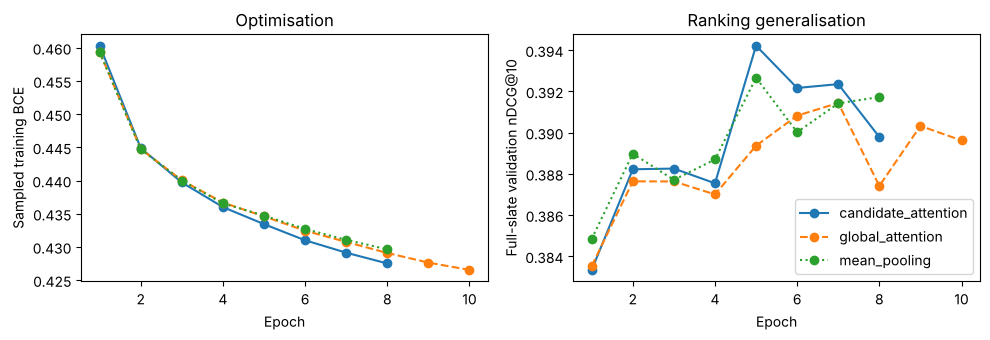

,model,partition,impressions,AUC,MRR,nDCG@5,nDCG@10
0,candidate_attention,train (complete slates),95071,0.7620,0.4200,0.4628,0.5155
1,candidate_attention,validation,61894,0.6587,0.3118,0.3349,0.3942
2,mean_pooling,train (complete slates),95071,0.7585,0.4167,0.4589,0.5120
3,mean_pooling,validation,61894,0.6591,0.3105,0.3331,0.3927


In [14]:
if importlib.util.find_spec('matplotlib') is not None:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for label, style in [('candidate_attention', '-'), ('global_attention', '--'), ('mean_pooling', ':')]:
        if label not in SELECTED_MODELS:
            continue
        curve = pd.read_csv((RUN_DIR / SELECTED_MODELS[label]['checkpoint']).parent / 'learning_curve.csv')
        axes[0].plot(curve['epoch'], curve['train_sampled_bce'], style, marker='o', label=label)
        axes[1].plot(curve['epoch'], curve['nDCG@10'], style, marker='o', label=label)
    axes[0].set(xlabel='Epoch', ylabel='Sampled training BCE', title='Optimisation')
    axes[1].set(xlabel='Epoch', ylabel='Full-slate validation nDCG@10', title='Ranking generalisation')
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160)
    plt.show()

training_rows_ = []
for label in [m for m in ('candidate_attention', 'mean_pooling') if m in SELECTED_MODELS]:
    record = SELECTED_MODELS[label]
    model = load_selected(record)
    metrics = ranking_metrics(train, predict(model, train, config_of(record), variant_of(record)))
    training_rows_.append({'model': label, 'partition': 'train (complete slates)', **metrics})
    training_rows_.append({'model': label, 'partition': 'validation', **ranking_metrics(validation, VALIDATION_SCORES[label])})
    del model
training_performance = pd.DataFrame(training_rows_)
training_performance.to_csv(RUN_DIR / 'training_performance.csv', index=False)
display(training_performance[['model', 'partition', 'impressions', *METRICS]].round(4))

### 10.5 Lock the selection

In [15]:
selection = {'selection_metric': 'validation nDCG@10', 'models': SELECTED_MODELS, 'selected_config': SELECTED_CONFIG,
             'fit_partition': 'train', 'test_used_for_selection': False}
write_json(RUN_DIR / 'selection_locked.json', selection)
write_json(RUN_DIR / 'run_manifest.json', {
    'pipeline': 'BT4222 candidate-aware attention + MLP (advanced model 2) with pooling ablations',
    'source_repository': 'JariusF10-8/bt4222',
    'processed_manifest_sha256': sha256_file(PROCESSED_DIR / 'manifest.json'),
    'feature_manifest_sha256': sha256_file(FEATURE_DIR / 'manifest.json'),
    'input_sha256': INPUT_HASHES, 'processed_directory': str(PROCESSED_DIR), 'feature_directory': str(FEATURE_DIR),
    'feature_transforms': PIPELINE.metadata(),
    'history': {'cap': HISTORY_CAP, 'order': 'most recent supplied clicks, right-aligned, repeats kept', 'padding': 0},
    'negative_sampling': {'k': NEGATIVES_PER_CLICK, 'source': 'same complete training impression',
                          'refresh': 'each epoch, seed + epoch', 'pointwise_weighting': 'one sampled row per BCE example'},
    'evaluation': {'candidate_pool': 'complete original impression', 'tie_seed': TIE_SEED,
                   'metric_impressions': 'at least one click and one non-click; excluded groups reported',
                   'MRR': 'mean reciprocal rank of clicked candidates, then mean over impressions'},
    'training': {'optimizer': 'AdamW', 'weight_decay': 'decoupled; matrices and embeddings only',
                 'loss': 'BCEWithLogitsLoss', 'batch_groups': BATCH_GROUPS, 'gradient_clip_norm': 5,
                 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'min_delta': MIN_DELTA, 'seed': SEED,
                 'trials': N_TRIALS, 'parameter_initialization': 'Xavier encoder/attention; Kaiming MLP; normal(0,0.01) embeddings'},
    'test_labels_read': False,
    'libraries': {'python': sys.version, 'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
                  'scikit-learn': sklearn.__version__},
    'device': str(DEVICE), 'created_at_utc': datetime.now(timezone.utc).isoformat()})
print('Completed model selection without reading test labels:', RUN_DIR)

Completed model selection without reading test labels: <repo>/outputs/models/candidate_attention/cand_attn_20261102_093038_280441


## 11. Test evaluation

Run only after all choices are final. This scores the locked checkpoints on test once and does not refit anything. Test uses the dev article metadata with the transforms fitted on training.

In [16]:
EVALUATE_TEST = True
if not EVALUATE_TEST:
    print('Test evaluation skipped. Keep test outcomes held out during development.')
else:
    require(COMPLETE_HANDOFF, 'Test evaluation needs the complete handoff.')
    require(not (RUN_DIR / 'test_evaluation_complete.json').exists(),
            'This run already evaluated test. Reuse its saved metrics rather than selecting settings on test.')
    locked = json.loads((RUN_DIR / 'selection_locked.json').read_text())
    require(locked['models'] == json.loads(json.dumps(SELECTED_MODELS, default=str)),
            'Selected models differ from the locked settings')
    test = read_partition('test')
    require(validation['events']['timestamp'].max() < test['events']['timestamp'].min(), 'Validation/test chronology overlaps')
    require(not set(test['events']['event_key']) & (set(train['events']['event_key']) | set(validation['events']['event_key'])),
            'Test event keys overlap earlier partitions')
    attach_cohorts(test, TRAIN_USERS, TRAIN_ARTICLES)
    PIPELINE.transform(test)
    records = []
    for name, record in SELECTED_MODELS.items():
        model = load_selected(record)
        scores = predict(model, test, config_of(record), variant_of(record))
        metrics = ranking_metrics(test, scores)
        records.append({'model': name, 'seed': record['seed'], **metrics, **test['exposure_shares']})
        cohort_report(test, scores).to_csv(RUN_DIR / f'test_cohorts_{name}.csv', index=False)
        if SAVE_PREDICTIONS:
            test['candidates'].assign(ranking_score=scores).to_csv(
                RUN_DIR / f'test_predictions_{name}.csv.gz', index=False, compression='gzip')
        del model
    test_results = pd.DataFrame(records)
    test_results.to_csv(RUN_DIR / 'test_results.csv', index=False)
    write_json(RUN_DIR / 'test_evaluation_complete.json', {'models': list(SELECTED_MODELS), 'input_sha256': INPUT_HASHES,
               'metrics': records, 'timestamp_utc': datetime.now(timezone.utc).isoformat()})
    display(test_results[['model', 'seed', 'impressions', *METRICS]].round(4))
    if RUN_EXTRA_SEEDS:
        grouped = test_results.assign(setting=test_results['model'].str.replace(r'_seed\d+$', '', regex=True))
        test_seed_summary = grouped.groupby('setting')[METRICS].agg(['mean', 'std', 'count'])
        test_seed_summary = test_seed_summary.loc[test_seed_summary[('nDCG@10', 'count')] > 1]
        test_seed_summary.to_csv(RUN_DIR / 'test_seed_summary.csv')
        display(test_seed_summary.round(4))
    print('Final test results saved. Do not revise hyperparameters in response to these results.')

,model,seed,impressions,AUC,MRR,nDCG@5,nDCG@10
0,candidate_attention,42,73152,0.6377,0.2997,0.3290,0.3925
1,mean_pooling,42,73152,0.6378,0.2974,0.3284,0.3906
2,global_attention,42,73152,0.6402,0.2971,0.3273,0.3900
3,no_side_features,42,73152,0.6360,0.2966,0.3258,0.3881
4,with_history_ctr,42,73152,0.6487,0.3139,0.3443,0.4056
5,entity_prominence,42,73152,0.6344,0.2979,0.3281,0.3902
6,candidate_attention_seed43,43,73152,0.6319,0.3038,0.3320,0.3930
7,candidate_attention_seed44,44,73152,0.6384,0.2942,0.3233,0.3874
8,mean_pooling_seed43,43,73152,0.6341,0.3019,0.3293,0.3918
9,mean_pooling_seed44,44,73152,0.6335,0.2946,0.3234,0.3873


AUC                   MRR                nDCG@5  \
                       mean     std count    mean     std count    mean   
setting                                                                   
candidate_attention  0.6360  0.0036     3  0.2992  0.0048     3  0.3281   
mean_pooling         0.6351  0.0024     3  0.2980  0.0037     3  0.3271   

                                  nDCG@10                
                        std count    mean     std count  
setting                                                  
candidate_attention  0.0044     3  0.3910  0.0031     3  
mean_pooling         0.0032     3  0.3899  0.0023     3

Final test results saved. Do not revise hyperparameters in response to these results.


## 12. Findings

This run used a local copy of the group's preprocessing and feature bundle (`v1`, `unified_local`) on a 2-core CPU. Running in Colab with the default versions reads the shared Drive folders, so the numbers may differ slightly.

**Selected model:** `trial_03`, validation nDCG@10 0.3942. Article dimension 64, 4 heads, hidden layers [128, 64], dropout 0.1, learning rate 0.001, weight decay 0.00001, history length 50. It has 81,129 parameters and was best at epoch 5 of 8. The 12 trials ranged from 0.3845 to 0.3942.

**Tuning**

- Dimension 64 beat 128 for every number of heads (trials 00 to 05), even though 128 has 2.2 times the parameters.
- With dimension 64, more heads helped a little: 0.3925, 0.3936 and 0.3942 for 1, 2 and 4 heads.
- The random trials changed several settings at once, so they cannot separate the effect of dropout, learning rate or history length. `trial_10` was still improving when it reached 15 epochs.
- Validation nDCG@10 moves by up to 0.003 between epochs, so small gaps between trials are noise. The test result is the fairer estimate.

**Ablations (seed 42)**

| Version | Validation nDCG@10 | Selected minus this (95% CI) | Test nDCG@10 |
|---|---|---|---|
| Candidate attention (selected) | 0.3942 | | 0.3925 |
| Mean pooling | 0.3927 | 0.0016 (0.0003 to 0.0028) | 0.3906 |
| Global attention | 0.3914 | 0.0028 (0.0014 to 0.0042) | 0.3900 |
| No engineered features | 0.3899 | 0.0043 (0.0025 to 0.0061) | 0.3881 |
| With CTR features | 0.3939 | 0.0003 (-0.0014 to 0.0020) | 0.4056 |
| Prominence entity vector | 0.3937 | 0.0005 (-0.0011 to 0.0020) | 0.3902 |

**Three seeds (42, 43, 44), mean and standard deviation**

| Version | Validation nDCG@10 | Test nDCG@10 | Test AUC |
|---|---|---|---|
| Candidate attention | 0.3931 (0.0014) | 0.3910 (0.0031) | 0.6360 (0.0036) |
| Mean pooling | 0.3912 (0.0029) | 0.3899 (0.0023) | 0.6351 (0.0024) |

**Takeaways**

1. Candidate attention beat mean pooling on all three seeds for both validation and test, but only by 0.001 to 0.004. That is about the same as the difference between seeds, so the gain is small.
2. Global attention was the weakest pooling and no better than a plain average. The benefit comes from using the candidate as the query.
3. The attention weights are close to equal (normalised entropy 0.95). Clicks in the candidate's subcategory get about 1.4 times their equal share. With TF-IDF text and mixed histories there is not much for attention to pick out, which is why mean pooling comes close.
4. The gain over mean pooling is not larger for long histories. Every history length group has an interval that includes zero. The gain over global attention for users with no history is not caused by attention, since an empty history is zero in every version.
5. The engineered features matter more than the pooling choice. Removing them cost 0.0043.
6. Prominence and uniform entity vectors give the same result, so `uniform` is kept.
7. CTR features did not help on validation, so they were not selected. On test they scored 0.4056, which is 0.013 higher. The model is not changed based on test, but this is worth discussing together with the history mode used for the CTR features.
8. Cold users do almost as well as warm users because the model uses content instead of IDs. On test, cold users (90% of impressions) scored 0.3922 and warm users 0.3952. Users with no history clicks scored 0.3069.
9. On complete training impressions nDCG@10 is 0.5155 (AUC 0.762), against 0.3942 (0.659) on validation. Early stopping and dropout limit overfitting, but part of the gap comes from new articles, since half of the validation exposures are articles not seen in training.

**Limitations:** TF-IDF instead of a pretrained text encoder, a 12 trial search on one seed, and one seed for most ablations.

### Saved files

Everything is saved in the run folder:

- `trials_search.csv`, `search_configs.*`, and each trial's `learning_curve.csv` and `best.pt`
- `selected_*.json`, `selected_*.csv` and `selection_locked.json`: the chosen settings and validation results
- `validation_*.csv`, `training_performance.csv` and `learning_curves.png`: diagnostics
- `test_*.csv` and `test_evaluation_complete.json`: test results
- `feature_transforms.json` and `run_manifest.json`: fitted transforms, input hashes and settings

## References

- Zhou et al. (2018). Deep Interest Network for Click-Through Rate Prediction. KDD.
- Wang et al. (2018). DKN: Deep Knowledge-Aware Network for News Recommendation. WWW.
- Wu et al. (2019). Neural News Recommendation with Multi-Head Self-Attention. EMNLP.
- Wu et al. (2020). MIND: A Large-scale Dataset for News Recommendation. ACL.
- Vaswani et al. (2017). Attention Is All You Need. NeurIPS.
- Rendle et al. (2020). Neural Collaborative Filtering vs. Matrix Factorization Revisited. RecSys.